# 00 · Ingesta en la nube: landing → Bronze

**Proyecto:** Minería aurífera y deforestación en el corredor La Pampa, Huepetuhe y Mazuko (Madre de Dios, Perú).

En este notebook todo ocurre dentro de Databricks:

1. **Landing:** los archivos oficiales (SERNANP, Geobosques-MINAM, GADM, OpenStreetMap) llegan al Volume tal como los publica cada institución.
2. **Ingesta cloud-to-cloud:** Sentinel-2 (AWS Open Data) y Hansen GFC (Google Cloud Storage) se leen directamente desde sus nubes de origen, solo los bloques del área de estudio.
3. **Bronze:** todo queda recortado y alineado a una grilla común UTM 19S de 20 m, en teselas de 512 px.

| Zona | Contenido | Granularidad |
|---|---|---|
| Landing | zip/shp/tif/xlsx originales | archivo |
| Bronze | teselas GeoTIFF alineadas + vectores recortados + metadatos | tesela |
| Silver | compuestos anuales sin nubes, índices espectrales, capas oficiales | píxel de 20 m |
| Gold | indicadores por hexágono H3 + covariables | hexágono (~0.1 km²) |

In [0]:
%pip install -q rasterio pyproj h3 geopandas shapely esda libpysal spreg pykrige scikit-gstat mapclassify pystac-client openpyxl
dbutils.library.restartPython()

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import sys, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Raíz del repositorio (Git folder en Databricks o clon local)
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))

from geocloud import config as C, dbx
spark = dbx.get_spark()
VOL = dbx.volume_path()
FIG = Path(VOL) / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Databricks:", dbx.is_databricks(), "| Volume:", VOL)

Databricks: True | Volume: /Volumes/workspace/madre_dios_rs/raw


## 1. Unity Catalog y zona landing

In [0]:
dbx.setup_catalog(spark)
LANDING, BRONZE = Path(VOL) / "landing", Path(VOL) / "bronze"
BRONZE.mkdir(parents=True, exist_ok=True)
grid = C.Grid()
print(f"Grilla: {grid.width} x {grid.height} píxeles de {grid.res} m = {grid.width*grid.height/1e6:.1f} M por banda, "
      f"{grid.n_tiles[0]} x {grid.n_tiles[1]} teselas de {grid.tile} px")

import pandas as pd
inv = pd.DataFrame([{"fuente": p.parent.name, "archivo": p.name, "MB": round(p.stat().st_size / 1e6, 1)}
                    for p in sorted(LANDING.rglob("*")) if p.is_file()])
dbx.show(inv)

Grilla: 3250 x 1950 píxeles de 20 m = 6.3 M por banda, 4 x 7 teselas de 512 px


,fuente,archivo,MB
0,gadm,gadm41_PER_3.json.zip,1.0
1,geobosques,Bosque_NoBosque_Perdida_2001_2025_Raster.zip,51.1
2,geobosques,Bosque_y_Perdida_de_Bosque_por_Categorias_Terr...,0.1
3,geobosques,Bosque_y_Perdida_de_Bosque_por_Departamentos_a...,0.3
4,geobosques,Bosque_y_perdida_de_bosques_por_Distrito_al_20...,0.2
5,geobosques,Mapa de Riesgo de Deforestacion.zip,12.4
6,geobosques,Perdida_2001_2025_Raster.zip,46.1
7,osm_geofabrik,peru-261108-free.shp.zip,622.4
8,sernanp,ANP Nacional Definitivas.zip,3.2
9,sernanp,Zonas de Amortiguamiento.zip,6.6


## 2. Fuentes oficiales: landing → Bronze

- **SERNANP:** ANP de administración nacional definitivas y zonas de amortiguamiento.
- **Geobosques (MINAM):** pérdida anual 2001-2025 (separa pérdida antrópica y natural en 2025), cobertura bosque/no bosque 2025 y mapa de riesgo de deforestación.
- **GADM 4.1:** distritos. **OpenStreetMap (Geofabrik):** vías principales y ríos.

Los shapefiles se leen dentro del zip con GDAL (`/vsizip`) y con filtro espacial, sin descomprimir el país completo.

In [0]:
from geocloud import ingest
resumen_ingesta = ingest.ingest_all(LANDING, BRONZE)
resumen_ingesta

[SERNANP] areas_protegidas_sernanp: 2 polígonos -> Bahuaja-Sonene, Tambopata
[SERNANP] zonas_amortiguamiento: 3 polígonos -> Bahuaja-Sonene, Tambopata, Amarakaeri
[GADM] 10 distritos de Madre de Dios
[OSM] vías principales: 70 | ríos: 67 | cauces (ríos + quebradas): 92 | poblados: 13 (Mazuko, Alto Libertad, Santa Rita Baja, Santa Rosa, Puerto Mazuko, Tazon)
[Geobosques] Perdida_2001_2025.tif: valores en el área {0: 4623567, 1: 13395, 2: 15149, 3: 18717, 4: 26890, 5: 11823, 6: 15312, 7: 23078, 8: 35709, 9: 26849, 10: 75121, 11: 71990, 12: 84061, 13: 62463, 14: 65772, 15: 119126, 16: 78545, 17: 148554, 18: 146008, 19: 112910, 20: 120328, 21: 78861, 22: 105398, 23: 89194, 24: 78073, 25: 88787, 26: 1820}
[Geobosques] Bosque_No_Bosque_2025.tif: valores en el área {1: 309966, 2: 1623326, 3: 88787, 4: 4057208, 5: 258213}
[Geobosques] Riesgo_Deforestacion_2018.tif: valores en el área {1: 6904, 2: 601998, 3: 646596, 4: 1618253, 5: 2002982, 15: 1460767}
[Geobosques] 28 teselas | 3 tablas oficial

{'sernanp': {'areas_protegidas_sernanp': 2, 'zonas_amortiguamiento': 3},
 'gadm': 10,
 'osm': 175,
 'geobosques': 28}

## 3. Descarga satelital cloud-to-cloud

Sentinel-2 y Hansen están publicados como *Cloud Optimized GeoTIFF*: con lecturas HTTP por rangos
se transfieren solo los bloques del área de estudio (≈ 2 % de cada escena).

En Databricks Free Edition la salida a internet requiere verificar la cuenta con LinkedIn.
Si no está disponible, se usa el plan B: `scripts/download_data.py` en local y `databricks fs cp` al Volume.

**Control de calidad radiométrico.** Desde el *processing baseline* 04.00 (2022) ESA suma +1000 a los DN.
La colección Collection 1 lo corrige de forma homogénea; la colección antigua `sentinel-2-l2a` (usada solo
cuando Collection 1 no tiene escenas) ya trae el offset aplicado. Los años descargados antes de esta
verificación se detectan y se vuelven a descargar automáticamente.

In [0]:
from geocloud import download
DESCARGAR = True          # False para reutilizar lo que ya está en el Volume

meta = BRONZE / "s2_items.csv"
prev = pd.read_csv(meta) if meta.exists() else pd.DataFrame(columns=["year", "collection"])
if "offset_aplicado_por_proveedor" not in prev:
    prev["offset_aplicado_por_proveedor"] = pd.NA
REDESCARGAR_ANIOS = sorted(prev.loc[(prev["collection"] == "sentinel-2-l2a") & (prev["year"] >= 2022)
                                    & prev["offset_aplicado_por_proveedor"].isna(), "year"].unique().tolist())
print("Años a volver a descargar por control radiométrico:", REDESCARGAR_ANIOS)

conectividad = download.has_internet()
print(conectividad)
if DESCARGAR and all(conectividad.values()):
    if REDESCARGAR_ANIOS:
        download.purge_years(BRONZE, REDESCARGAR_ANIOS)
    if not (BRONZE / "hansen").exists():
        download.run_hansen(BRONZE)
    items = download.run_s2(BRONZE, years=C.YEARS, max_items=C.MAX_ITEMS_PER_YEAR, workers=8)
elif not (BRONZE / "s2").exists():
    print("Sin salida a internet y sin datos en bronze/s2: ejecutar el plan B (download_data.py + databricks fs cp).")
else:
    print("Usando las teselas Sentinel-2 y Hansen ya cargadas en el Volume.")

Años a volver a descargar por control radiométrico: []
{'https://earth-search.aws.element84.com/v1': True, 'https://storage.googleapis.com/earthenginepartners-hansen/GFC-2024-v1.12/lossyear.txt': True}
[S2] 2018: 22 escenas en sentinel-2-c1-l2a, 12 seleccionadas (2 teselas MGRS, nubosidad media 6.6%)
[S2] 2020: 37 escenas en sentinel-2-c1-l2a, 12 seleccionadas (2 teselas MGRS, nubosidad media 6.2%)
[S2] 2022: 33 escenas en sentinel-2-l2a, 12 seleccionadas (4 teselas MGRS, nubosidad media 15.2%)
[S2] 2024: 45 escenas en sentinel-2-c1-l2a, 12 seleccionadas (2 teselas MGRS, nubosidad media 1.9%)
[S2] 2025: 73 escenas en sentinel-2-c1-l2a, 12 seleccionadas (2 teselas MGRS, nubosidad media 5.5%)
  [1/60] S2A_T19LDF_20180828T145854_L2A: ya existía
  [2/60] S2B_T19LCF_20180909T145159_L2A: ya existía
  [3/60] S2A_T19LDF_20180818T150209_L2A: ya existía
  [4/60] S2A_T19LCF_20180907T150208_L2A: ya existía
  [5/60] S2A_T19LDF_20180907T150208_L2A: ya existía
  [6/60] S2B_T19LDF_20180909T145159_L2A:

## 4. Inventario distribuido (sin abrir los archivos)

`binaryFile` lista los GeoTIFF como un DataFrame distribuido. Spark infiere las columnas `year` y `tile`
de la estructura `year=YYYY/tile=rRR_cCC` (particionamiento estilo Hive).

In [0]:
from pyspark.sql import functions as F

s2_files = (spark.read.format("binaryFile").option("pathGlobFilter", "*.tif")
            .load(f"{VOL}/bronze/s2").drop("content")
            .withColumn("item_id", F.regexp_extract("path", r"([^/]+)\.tif$", 1)))
dbx.show(s2_files.groupBy("year").agg(F.countDistinct("item_id").alias("escenas"), F.count("*").alias("teselas"),
                                      F.round(F.sum("length") / 1e9, 2).alias("GB")).orderBy("year"))
tot = s2_files.agg(F.count("*").alias("n"), F.sum("length").alias("b")).first()
n_val = s2_files.select("year", "item_id").distinct().count() * grid.width * grid.height * 7
print(f"Archivos: {tot.n:,} | {tot.b/1e9:.2f} GB comprimidos | {n_val/1e9:.2f} mil millones de valores raster")

DataFrame[year: int, escenas: bigint, teselas: bigint, GB: double]

Archivos: 869 | 1.42 GB comprimidos | 2.66 mil millones de valores raster


## 5. Tablas Bronze

In [0]:
items = pd.read_csv(BRONZE / "s2_items.csv")
items = items[items["status"] == "descargado"]
dbx.save_table(spark.createDataFrame(items.astype({"year": int})), "bronze_s2_items")
dbx.save_table(s2_files, "bronze_s2_files")

import geopandas as gpd
for f in sorted((BRONZE / "vector").glob("*.geojson")):
    g = gpd.read_file(f)
    g["wkt"] = g.geometry.to_wkt()
    dbx.save_table(spark.createDataFrame(pd.DataFrame(g.drop(columns="geometry")).astype(str)), "bronze_vec_" + f.stem)
    print(f"bronze_vec_{f.stem:30s} {len(g):5d} geometrías")

bronze_vec_areas_protegidas_sernanp           2 geometrías
bronze_vec_cauces                            92 geometrías
bronze_vec_distritos_madre_de_dios           10 geometrías
bronze_vec_poblados                          13 geometrías
bronze_vec_rios                              67 geometrías
bronze_vec_vias                              70 geometrías
bronze_vec_zonas_amortiguamiento              3 geometrías


In [0]:
# Tablas oficiales de Geobosques: pérdida por distrito (para contrastar con nuestras estimaciones)
for t in sorted((BRONZE / "tablas").glob("*Distrito*.xlsx")):
    tab = pd.read_excel(t)
    mdd = tab[tab.astype(str).apply(lambda r: r.str.upper().str.contains("MADRE DE DIOS")).any(axis=1)]
    print(t.name, "| filas Madre de Dios:", len(mdd))
    dbx.show(mdd.head(20))

Bosque_y_perdida_de_bosques_por_Distrito_al_2025.xlsx | filas Madre de Dios: 11


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31,Unnamed: 32,Unnamed: 33,Unnamed: 34
277,Madre de Dios,Tambopata,Tambopata,170101,44457.3,1053.45,836.46,748.98,921.96,1777.14,745.92,860.67,1565.28,820.08,1610.46,1042.11,1357.74,1098.36,1127.79,1199.43,1889.1,966.24,1512.18,791.01,1657.62,1103.76,1392.93,793.53,1282.86,28155.06,800.46,133.74,934.2,43632.54,1966753.89
278,Madre de Dios,Tambopata,Inambari,170102,13140.9,674.82,794.7,898.83,1360.44,627.3,803.43,1112.58,1708.2,1217.97,3479.49,3103.47,3805.56,3123.99,3580.83,5555.43,4136.13,6823.53,6786.54,5238.72,5920.47,4466.34,6833.34,5915.07,5181.84,83149.02,6786.9,219.6,7006.5,25943.94,359139.6
279,Madre de Dios,Tambopata,Las Piedras,170103,31954.5,1151.64,906.84,838.35,1170.27,2341.98,612,966.15,1561.86,787.23,1911.06,1349.28,1146.15,1294.29,2062.71,1764,2261.97,1423.62,2882.52,1813.59,2527.11,2437.38,1557,1646.73,1924.2,38337.93,1083.33,30.51,1113.84,11765.88,697175.37
280,Madre de Dios,Tambopata,Laberinto,170104,11852.73,470.43,529.2,548.19,574.56,624.78,603.81,449.19,787.5,532.44,1291.14,785.88,1080.27,1141.92,1253.7,1116.9,1184.67,1761.57,1722.15,1423.71,2075.58,1958.13,2029.23,1872.18,1535.76,27352.89,1675.08,96.12,1771.2,9884.16,218815.83
281,Madre de Dios,Manu,Manu,170201,15154.29,576.27,501.21,180.36,479.16,389.16,102.6,218.52,214.47,125.28,333,494.01,164.43,215.91,538.11,284.58,344.97,402.75,310.23,56.25,215.73,139.41,196.56,142.92,154.62,6780.51,232.11,287.19,519.3,32845.5,811094.22
282,Madre de Dios,Manu,Fitzcarrald,170202,5643.54,76.95,93.87,180.63,220.14,79.65,58.41,266.04,134.28,98.28,90.54,91.26,97.02,135.72,775.17,260.55,175.95,181.44,236.7,216.45,214.56,278.73,292.59,176.4,294.03,4725.36,301.23,129.42,430.65,25532.1,1032238.62
283,Madre de Dios,Manu,Madre De Dios,170203,8348.22,462.15,364.77,821.16,744.39,324.45,1162.53,1670.49,1164.51,652.32,2622.51,1640.07,1714.59,1729.44,1610.37,2255.04,1875.24,3219.75,2718.99,3106.62,3533.67,2765.7,4562.82,3584.25,2887.38,47193.21,2968.83,196.83,3165.66,31504.41,698240.52
284,Madre de Dios,Manu,Huepetuhe,170204,13335.39,160.2,245.34,457.11,506.79,305.37,233.46,550.98,397.35,294.3,984.42,850.32,690.57,817.11,655.65,980.82,506.34,1597.32,1482.57,721.44,938.97,645.57,1749.69,964.08,822.78,17558.55,447.75,5.4,453.15,6377.22,115323.93
285,Madre de Dios,Tahuamanu,Iñapari,170301,8237.07,208.08,200.34,146.07,410.85,316.17,419.49,309.96,649.8,306.27,552.96,650.88,586.71,966.15,1064.43,1036.08,1072.89,2360.16,1737.63,2820.69,1650.6,2804.04,1506.24,472.41,2780.01,25028.91,398.34,68.49,466.83,13354.83,1341284.85
286,Madre de Dios,Tahuamanu,Iberia,170302,16781.31,387.45,371.79,478.35,793.8,735.75,651.78,495.54,1614.87,549.45,931.5,955.53,616.77,1104.03,1470.42,1626.12,2283.93,3071.7,2006.82,3404.79,1728.63,2879.37,1965.24,995.49,7146.09,38265.21,184.86,19.71,204.57,1900.71,203268.06


## 6. Control de calidad visual

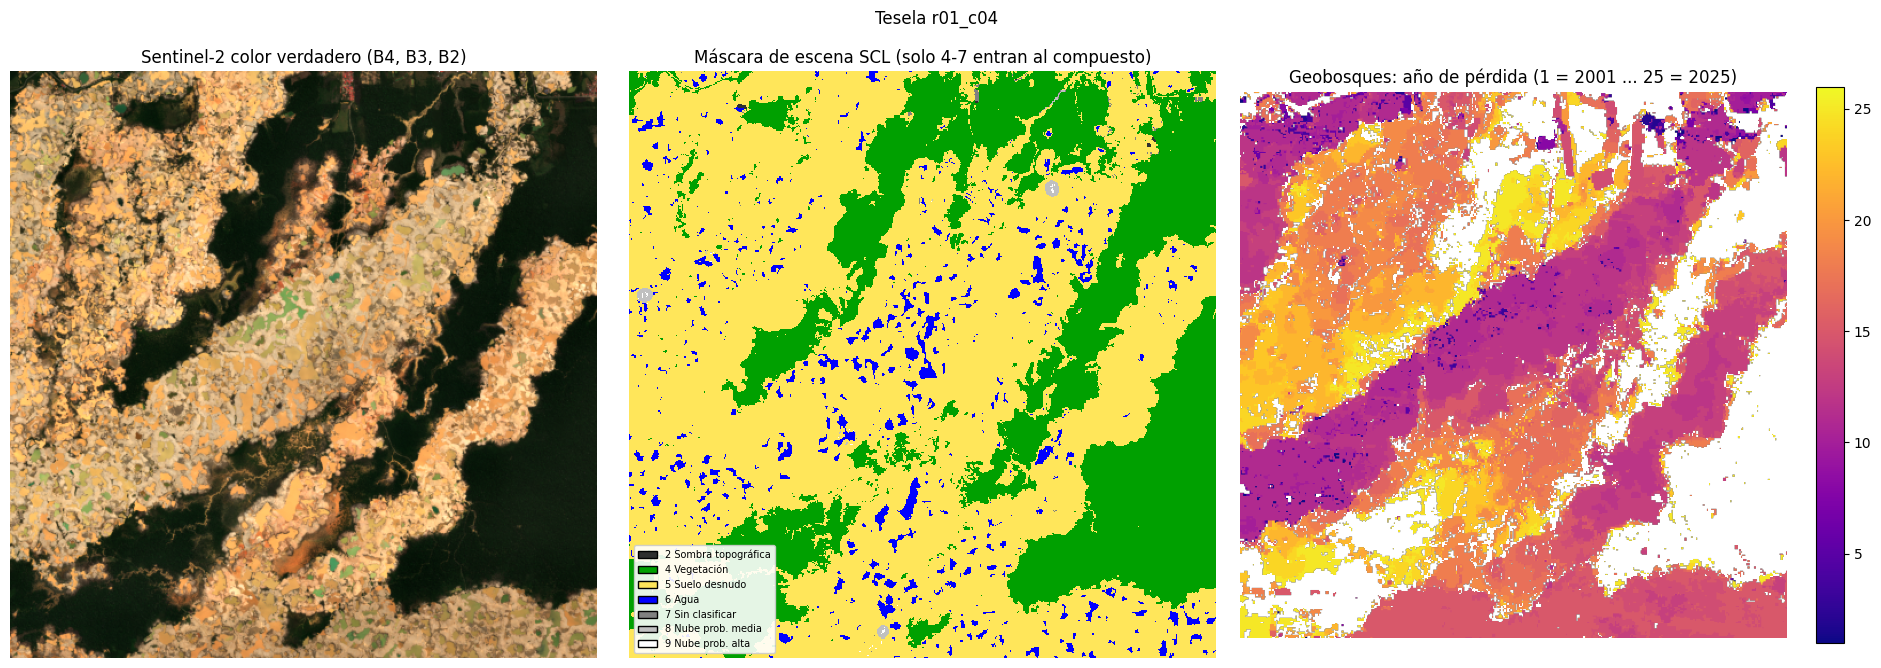

In [0]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from matplotlib.colors import ListedColormap

sample = (spark.table(dbx.tbl("bronze_s2_files")).orderBy(F.desc("length"))
          .select("path").first().path.replace("dbfs:", "").replace("file:", ""))
tile = sample.split("tile=")[1].split("/")[0]
with rasterio.open(sample) as ds:
    arr = ds.read().astype(float)
rgb = np.clip(np.dstack([arr[2], arr[1], arr[0]]) / 10000, 0, None)
rgb = np.clip(rgb / np.nanpercentile(rgb[rgb > 0], 98), 0, 1)

from matplotlib.patches import Patch
scl_clases = {0: ("Sin dato", "#000000"), 1: ("Saturado", "#ff0000"), 2: ("Sombra topográfica", "#2f2f2f"),
              3: ("Sombra de nube", "#643200"), 4: ("Vegetación", "#00a000"), 5: ("Suelo desnudo", "#ffe65a"),
              6: ("Agua", "#0000ff"), 7: ("Sin clasificar", "#808080"), 8: ("Nube prob. media", "#c0c0c0"),
              9: ("Nube prob. alta", "#ffffff"), 10: ("Cirro", "#64c8ff"), 11: ("Nieve", "#ff96ff")}
cmap_scl = ListedColormap([scl_clases[i][1] for i in range(12)])
fig, ax = plt.subplots(1, 3, figsize=(19, 6.5))
ax[0].imshow(rgb); ax[0].set_title("Sentinel-2 color verdadero (B4, B3, B2)")
ax[1].imshow(arr[6], cmap=cmap_scl, vmin=-0.5, vmax=11.5, interpolation="nearest")
presentes = sorted(int(v) for v in np.unique(arr[6]))
ax[1].legend(handles=[Patch(facecolor=scl_clases[v][1], edgecolor="k", label=f"{v} {scl_clases[v][0]}") for v in presentes],
             loc="lower left", fontsize=7, framealpha=0.9)
ax[1].set_title("Máscara de escena SCL (solo 4-7 entran al compuesto)")
gb = BRONZE / "geobosques" / f"tile={tile}" / "geobosques.tif"
if gb.exists():
    with rasterio.open(gb) as ds:
        per = ds.read(1).astype(float)
    per[(per == 0) | (per > 26)] = np.nan
    im = ax[2].imshow(per, cmap="plasma", vmin=1, vmax=26); plt.colorbar(im, ax=ax[2], fraction=0.046)
    ax[2].set_title("Geobosques: año de pérdida (1 = 2001 ... 25 = 2025)")
for a in ax: a.axis("off")
plt.suptitle(f"Tesela {tile}", y=1.02); plt.tight_layout()
plt.savefig(FIG / "00_control_calidad.png", dpi=150); plt.show()